# Fairness of tolls

Who pays for the system optimum?

Every toll vector in the toll set produces the same system optimal flows, so they are equally efficient. They are not equally fair: they charge different links, so they take different amounts from different travellers. This notebook measures that on the three example networks (Braess `hearn-example`, `nine-node`, `sioux-falls`).

Travellers are grouped by O-D pair and all value time equally. For an O-D pair $w$ with $q_w$ travellers:

* $u^0_w$: travel time at the untolled user equilibrium, the situation before the intervention.
* $\pi_w$: travel time plus tolls at the tolled equilibrium. It is the same for every traveller of $w$, whatever route they take.
* $\sigma$: refund per traveller. $\sigma = \beta^T v^* / \sum_w q_w$.
* $u_w = \pi_w - \sigma$: net cost after the intervention, and $u_w / u^0_w$ the ratio that says whether $w$ gained (below 1) or lost (above 1).

**Fairness criteria**, following Fischer, Gairing and Paccagnan and other papers that study fairness. 

| | criterion | measured by |
|---|---|---|
| F1 | equal treatment: identical travellers get identical outcomes | the ratio slowest / fastest used route within an O-D pair (travel time only) |
| F2 | Pareto improvement: nobody is worse off | share of travellers with $u_w > u^0_w$ |
| F3 | bounded harm | $\eta = \max_w u_w / u^0_w$ |
| F4 | inequality | Gini coefficient of net cost over travellers, before and after |

**Toll methods.** The six of Hearn and Ramana, plus `MINHARM`, the first-best toll that minimises $\Upsilon$ when the revenue is refunded equally (a linear programme over the toll set). The functions are in `src/fair_tolling`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from aequilibrae import Project

from fair_tolling import assignment as fa
from fair_tolling import fairness as ff
from fair_tolling import tolling as ft

AE_DIR = Path("../ae-projects").resolve()
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

# color Pallete
COLOR = {"MSCP": "#2a78d6", "MINSYS": "#eb6834", "MINMAX": "#1baf7a", "RH": "#eda100",
         "MINHARM": "#e87ba4", "MINTB": "#008300", "MINTB_RH": "#6250d6"}
BETTER, WORSE, INK, MUTED = "#2a78d6", "#e34948", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ae", "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True, "text.color": INK,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9,
    "axes.titlesize": 10, "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200,
})

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")

## Solve for tolled equillibrium

`MINTB` and `MINTB_RH` do not solve under one minute for sioux falls so skipped.

In [2]:
NETWORKS = {
    "hearn-example": ["MSCP", "MINSYS", "MINMAX", "MINTB", "RH", "MINTB_RH", "MINHARM"],
    "nine-node": ["MSCP", "MINSYS", "MINMAX", "MINTB", "RH", "MINTB_RH", "MINHARM"],
    "sioux-falls": ["MSCP", "MINSYS", "MINMAX", "RH", "MINHARM"],
}
REVENUE_NEUTRAL = ("RH", "MINTB_RH")


def run_network(name, methods):
    """Solve one network; return its data, the outcome table per (method, refund) and the route flows."""
    project = Project()
    project.open(str(AE_DIR / name))
    matrix = f"{name}_demand"
    fa.solve_assignment(project, matrix, "ue", "UE")
    fa.solve_assignment(project, matrix, "so", "SO")
    outcomes, tolls = {}, {}
    for method in methods:
        ft.solve_tolls(project, matrix, method)
        tolls[method] = ft.load_tolls(project, f"toll_{method.lower()}")
        for refund in (False, True):
            outcomes[method, refund] = ff.evaluate(project, matrix, "so", f"toll_{method.lower()}", refund=refund)
    result = {
        "links": fa.load_links(project), "demand": fa.load_demand(project, matrix),
        "ue": fa.link_flows(project, "ue"), "so": fa.link_flows(project, "so"),
        "ue_paths": fa.path_flows(project, matrix, "ue"), "so_paths": fa.path_flows(project, matrix, "so"),
        "tolls": pd.DataFrame(tolls), "outcomes": outcomes, "nodes": project.network.nodes.data.set_index("node_id"),
    }
    project.close()
    return result


results = {name: run_network(name, methods) for name, methods in NETWORKS.items()}

In [3]:
def summary_table(result):
    """Fairness measures of every method, with the revenue kept and refunded."""
    rows = {}
    for (method, refund), outcome in result["outcomes"].items():
        if method in REVENUE_NEUTRAL and refund:
            continue
        label = "revenue neutral" if method in REVENUE_NEUTRAL else ("refunded" if refund else "kept")
        rows[method, label] = ff.fairness_summary(outcome)
    table = pd.DataFrame(rows).T.rename_axis(["method", "revenue"])
    table["toll_revenue_per_trip"] = [float((result["tolls"][m] * result["so"]).sum()) / result["demand"].sum() for m, _ in table.index]
    return table

summaries = {name: summary_table(result) for name, result in results.items()}
for name, table in summaries.items():
    ue_time, so_time = fa.total_time(results[name]["links"], results[name]["ue"]), fa.total_time(results[name]["links"], results[name]["so"])
    print(f"{name}: {len(results[name]['demand'])} O-D pairs, {results[name]['demand'].sum():,.0f} trips, "
          f"mean travel time UE {ue_time / results[name]['demand'].sum():.2f}, SO {so_time / results[name]['demand'].sum():.2f} "
          f"({100 * (1 - so_time / ue_time):.1f} % saved)")
    display(table.round(3))

hearn-example: 1 O-D pairs, 4,000 trips, mean travel time UE 82.01, SO 65.80 (19.8 % saved)


mean_cost_before  mean_net_cost  max_ratio  \
method   revenue                                                       
MSCP     kept                        82.01         89.990      1.097   
         refunded                    82.01         65.801      0.802   
MINSYS   kept                        82.01         67.988      0.829   
         refunded                    82.01         65.794      0.802   
MINMAX   kept                        82.01         78.982      0.963   
         refunded                    82.01         65.794      0.802   
MINTB    kept                        82.01         67.988      0.829   
         refunded                    82.01         65.794      0.802   
RH       revenue neutral             82.01         65.794      0.802   
MINTB_RH revenue neutral             82.01         65.794      0.802   
MINHARM  kept                        82.01         89.975      1.097   
         refunded                    82.01         65.794      0.802   

                          min_ratio  share_worse_off  gini_before  gini  \
method   revenue                                                          
MSCP     kept                 1.097              1.0          0.0   0.0   
         refunded             0.802              0.0          0.0   0.0   
MINSYS   kept                 0.829              0.0          0.0   0.0   
         refunded             0.802              0.0          0.0   0.0   
MINMAX   kept                 0.963              0.0          0.0   0.0   
         refunded             0.802              0.0          0.0   0.0   
MINTB    kept                 0.829              0.0          0.0   0.0   
         refunded             0.802              0.0          0.0   0.0   
RH       revenue neutral      0.802              0.0          0.0   0.0   
MINTB_RH revenue neutral      0.802              0.0          0.0   0.0   
MINHARM  kept                 1.097              1.0          0.0   0.0   
         refunded             0.802              0.0          0.0   0.0   

                          toll_revenue_per_trip  
method   revenue                                 
MSCP     kept                            24.189  
         refunded                        24.189  
MINSYS   kept                             2.193  
         refunded                         2.193  
MINMAX   kept                            13.187  
         refunded                        13.187  
MINTB    kept                             2.193  
         refunded                         2.193  
RH       revenue neutral                  0.000  
MINTB_RH revenue neutral                  0.000  
MINHARM  kept                            24.181  
         refunded                        24.181

nine-node: 4 O-D pairs, 100 trips, mean travel time UE 24.56, SO 22.54 (8.2 % saved)


mean_cost_before  mean_net_cost  max_ratio  \
method   revenue                                                       
MSCP     kept                       24.559         37.410      1.597   
         refunded                   24.559         22.462      0.968   
MINSYS   kept                       24.559         31.392      1.357   
         refunded                   24.559         22.537      0.992   
MINMAX   kept                       24.559         31.717      1.389   
         refunded                   24.559         22.537      1.011   
MINTB    kept                       24.559         31.401      1.357   
         refunded                   24.559         22.537      0.992   
RH       revenue neutral            24.559         22.537      0.968   
MINTB_RH revenue neutral            24.559         22.537      0.983   
MINHARM  kept                       24.559         33.041      1.367   
         refunded                   24.559         22.539      0.925   

                          min_ratio  share_worse_off  gini_before   gini  \
method   revenue                                                           
MSCP     kept                 1.480              1.0        0.011  0.008   
         refunded             0.880              0.0        0.011  0.013   
MINSYS   kept                 1.227              1.0        0.011  0.023   
         refunded             0.855              0.0        0.011  0.032   
MINMAX   kept                 1.228              1.0        0.011  0.026   
         refunded             0.842              0.3        0.011  0.037   
MINTB    kept                 1.227              1.0        0.011  0.023   
         refunded             0.855              0.0        0.011  0.032   
RH       revenue neutral      0.778              0.0        0.011  0.037   
MINTB_RH revenue neutral      0.857              0.0        0.011  0.022   
MINHARM  kept                 1.275              1.0        0.011  0.010   
         refunded             0.854              0.0        0.011  0.015   

                          toll_revenue_per_trip  
method   revenue                                 
MSCP     kept                            14.948  
         refunded                        14.948  
MINSYS   kept                             8.855  
         refunded                         8.855  
MINMAX   kept                             9.180  
         refunded                         9.180  
MINTB    kept                             8.864  
         refunded                         8.864  
RH       revenue neutral                 -0.000  
MINTB_RH revenue neutral                  0.000  
MINHARM  kept                            10.502  
         refunded                        10.502

sioux-falls: 528 O-D pairs, 360,600 trips, mean travel time UE 20.76, SO 19.95 (3.9 % saved)


mean_cost_before  mean_net_cost  max_ratio  \
method  revenue                                                       
MSCP    kept                       20.718         60.142      4.520   
        refunded                   20.718         19.951      2.431   
MINSYS  kept                       20.718         25.042      2.267   
        refunded                   20.718         19.949      1.598   
MINMAX  kept                       20.718         25.140      2.630   
        refunded                   20.718         19.949      1.436   
RH      revenue neutral            20.718         19.949      1.771   
MINHARM kept                       20.718         26.591      3.035   
        refunded                   20.718         19.949      1.235   

                         min_ratio  share_worse_off  gini_before   gini  \
method  revenue                                                           
MSCP    kept                 1.005            1.000        0.288  0.323   
        refunded           -18.357            0.463        0.288  0.974   
MINSYS  kept                 0.821            0.946        0.288  0.281   
        refunded            -1.465            0.372        0.288  0.353   
MINMAX  kept                 0.873            0.963        0.288  0.281   
        refunded            -1.514            0.371        0.288  0.354   
RH      revenue neutral      0.000            0.425        0.288  0.289   
MINHARM kept                 0.891            0.974        0.288  0.278   
        refunded            -1.923            0.435        0.288  0.371   

                         toll_revenue_per_trip  
method  revenue                                 
MSCP    kept                            40.191  
        refunded                        40.191  
MINSYS  kept                             5.093  
        refunded                         5.093  
MINMAX  kept                             5.192  
        refunded                         5.192  
RH      revenue neutral                  0.000  
MINHARM kept                             6.642  
        refunded                         6.642

## 1. Comparing travel time alone

Not everyone saves at system optimum
Before any money changes hands: how does the travel time of each group change between the UE and the SO? Route flows come from the flow decomposition (`assignment.path_flows`). At the UE all travellers of an O-D pair need the same time. At the SO they are split over routes of different length. 

Sioux Falls: 40 % of trips belong to O-D pairs whose mean travel time rises at the SO; largest rise 24 %, largest fall 39 %; largest slowest/fastest spread within a pair 1.48


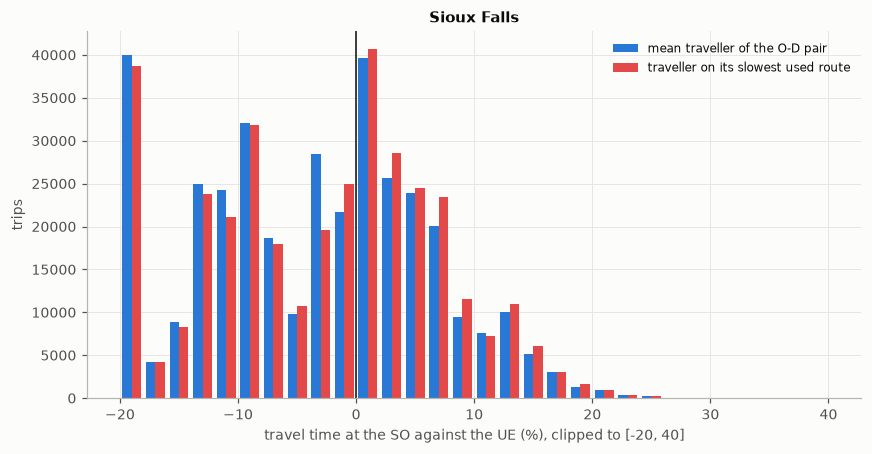

In [6]:
def time_ranges(result):
    """Per O-D pair: UE time, and the fastest, mean and slowest used route at the SO."""
    table = ff.od_times(result["so_paths"]).join(ff.od_times(result["ue_paths"]).mean_time.rename("ue_time"))
    return table.join(result["demand"])

# Sioux Falls: change of travel time per O-D pair, SO against UE
table = time_ranges(results["sioux-falls"])
change = 100 * (table.mean_time / table.ue_time - 1)
slow = 100 * (table.slowest / table.ue_time - 1)
bins = np.arange(-20, 42, 2)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist([change.clip(-20, 40), slow.clip(-20, 40)], bins=bins, weights=[table.demand, table.demand],
        color=[BETTER, WORSE], label=["mean traveller of the O-D pair", "traveller on its slowest used route"])
ax.axvline(0, color=INK, lw=1)
ax.set(xlabel="travel time at the SO against the UE (%), clipped to [-20, 40]", ylabel="trips",
       title="Sioux Falls")
ax.legend(fontsize=8)
plt.tight_layout()
save(fig, "travel_time_before_after")

share_slower = table.demand[change > 0.1].sum() / table.demand.sum()
spread = (table.slowest / table.fastest).max()
print(f"Sioux Falls: {100 * share_slower:.0f} % of trips belong to O-D pairs whose mean travel time rises at the SO; "
      f"largest rise {change.max():.0f} %, largest fall {-change.min():.0f} %; "
      f"largest slowest/fastest spread within a pair {spread:.2f}")

Sioux Falls: The mean traveller gains 3.9 %, but 40 % of trips belong to O-D pairs whose mean travel time rises, by up to 24 %. Others fall by up to 39 %.

## OD groups all methods for the nine node network
Four OD pairs. The black line is the cost before the intervention.

mean_net_cost  max_ratio  share_worse_off   gini
method   revenue                                                          
MSCP     kept                    37.410      1.597              1.0  0.008
         refunded                22.462      0.968              0.0  0.013
MINSYS   kept                    31.392      1.357              1.0  0.023
         refunded                22.537      0.992              0.0  0.032
MINMAX   kept                    31.717      1.389              1.0  0.026
         refunded                22.537      1.011              0.3  0.037
MINTB    kept                    31.401      1.357              1.0  0.023
         refunded                22.537      0.992              0.0  0.032
RH       revenue neutral         22.537      0.968              0.0  0.037
MINTB_RH revenue neutral         22.537      0.983              0.0  0.022
MINHARM  kept                    33.041      1.367              1.0  0.010
         refunded                22.539      0.925              0.0  0.015

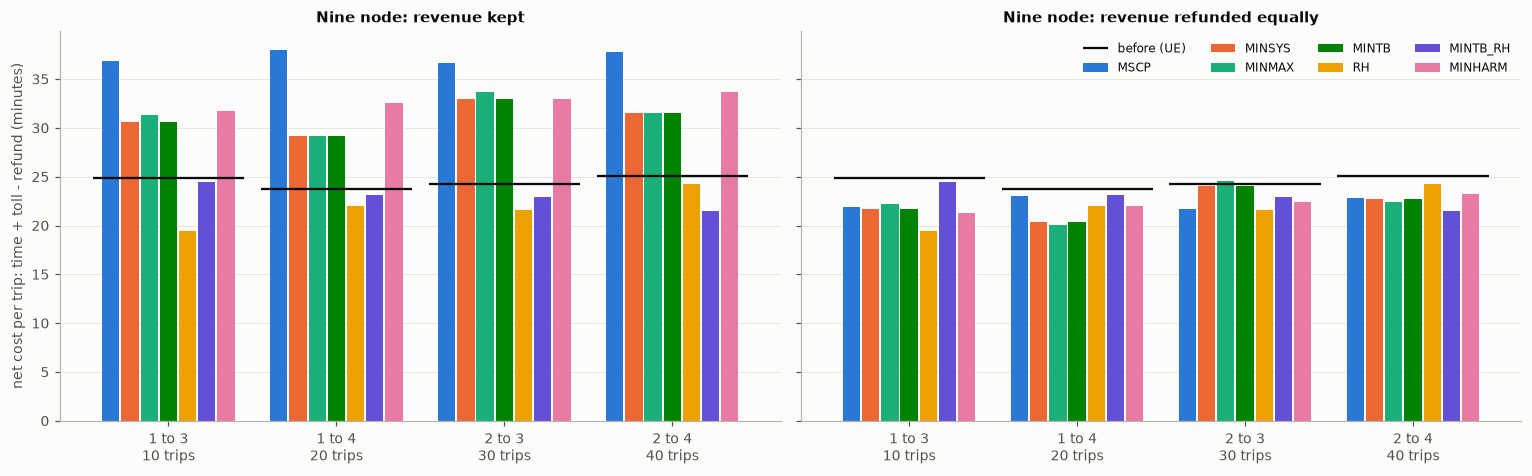

In [7]:
def group_bars(result, methods, title, name):
    outcomes = result["outcomes"]
    groups = result["demand"].index
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
    for ax, refund in zip(axes, (False, True)):
        width = 0.8 / len(methods)
        for k, method in enumerate(methods):
            x = np.arange(len(groups)) + (k - (len(methods) - 1) / 2) * width
            ax.bar(x, outcomes[method, refund].net_cost, width * 0.9, color=COLOR[method], label=method)
        before = outcomes[methods[0], False].cost_before
        for i, value in enumerate(before):
            ax.hlines(value, i - 0.45, i + 0.45, color=INK, lw=1.5, label="before (UE)" if i == 0 else None)
        ax.set_xticks(range(len(groups)), [f"{o} to {d}\n{q:.0f} trips" for (o, d), q in result["demand"].items()])
        ax.set_title(f"{title}: revenue {'refunded equally' if refund else 'kept'}")
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("net cost per trip: time + toll - refund (minutes)")
    axes[1].legend(ncol=4, fontsize=8, loc="upper right")
    plt.tight_layout()
    save(fig, name)

group_bars(results["nine-node"], NETWORKS["nine-node"], "Nine node", "nine_node_groups")
summaries["nine-node"][["mean_net_cost", "max_ratio", "share_worse_off", "gini"]].round(3)

## OD pairs Sioux Falls

528 O-D pairs. Each dot is one pair, sized by its trips: below the diagonal it gained, above it lost. The revenue is refunded equally in all panels.

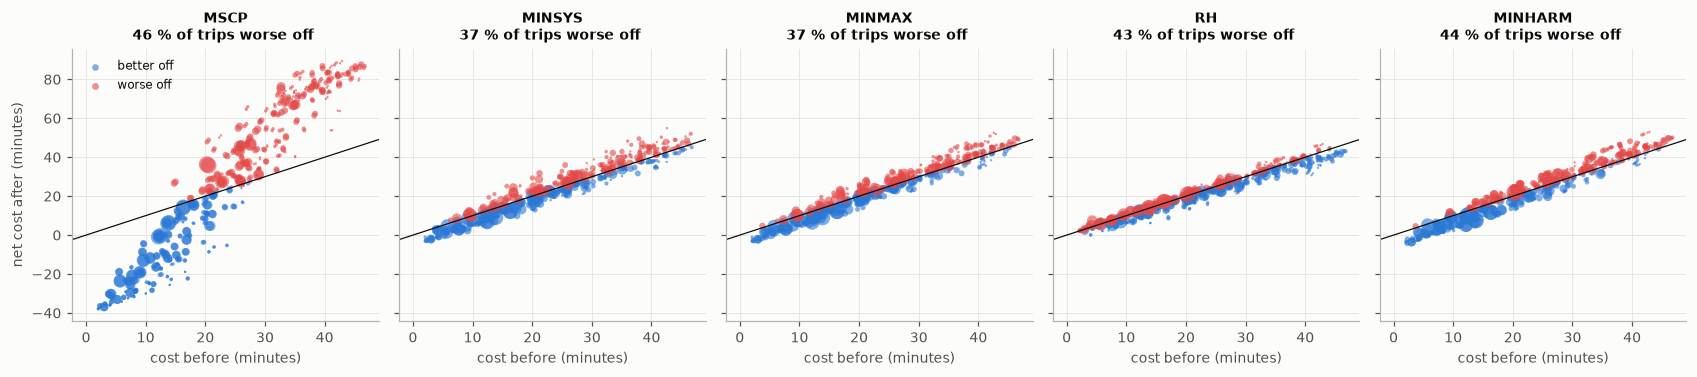

In [10]:
def winners_losers(result, methods, name):
    fig, axes = plt.subplots(1, len(methods), figsize=(3.1 * len(methods), 3.5), sharex=True, sharey=True)
    for ax, method in zip(axes, methods):
        outcome = result["outcomes"][method, True]
        worse = outcome.ratio > 1 + ff.WORSE_OFF
        for mask, color, label in ((~worse, BETTER, "better off"), (worse, WORSE, "worse off")):
            ax.scatter(outcome.cost_before[mask], outcome.net_cost[mask], s=outcome.demand[mask] / 40, color=color, alpha=0.6, lw=0, label=label)
        ax.axline((0, 0), slope=1, color=INK, lw=0.8)
        share = outcome.demand[worse].sum() / outcome.demand.sum()
        ax.set_title(f"{method}\n{100 * share:.0f} % of trips worse off ", fontsize=9)
        ax.set_xlabel("cost before (minutes)")
    axes[0].set_ylabel("net cost after (minutes)")
    axes[0].legend(fontsize=8, markerscale=0.6)
    plt.tight_layout()
    save(fig, name)

winners_losers(results["sioux-falls"], NETWORKS["sioux-falls"], "sioux_falls_winners_losers")

**with a uniform refund, short trips win and long trips lose**.

In [11]:
# def ratio_curves(result, methods, title, ax, refund=True):
#     for method in methods:
#         outcome = result["outcomes"][method, refund].sort_values("ratio")
#         share = outcome.demand.cumsum() / outcome.demand.sum()
#         ax.step(outcome.ratio, share, where="post", color=COLOR[method], lw=2, label=method)
#     ax.axvline(1, color=INK, lw=0.8)
#     ax.set(xlabel="net cost after / cost before", ylabel="share of trips at or below", title=title)

# fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
# ratio_curves(results["sioux-falls"], NETWORKS["sioux-falls"], "Sioux Falls: revenue kept by the operator", axes[0], refund=False)
# ratio_curves(results["sioux-falls"], NETWORKS["sioux-falls"], "Sioux Falls: revenue refunded equally", axes[1], refund=True)
# axes[1].set_xlim(0, 2.5)
# axes[0].legend(fontsize=8)
# axes[1].annotate("gain", (0.97, 0.04), ha="right", color=MUTED)
# axes[1].annotate("lose", (1.03, 0.04), ha="left", color=MUTED)
# plt.tight_layout()
# save(fig, "sioux_falls_ratio_distribution")
# summaries["sioux-falls"][["mean_net_cost", "max_ratio", "share_worse_off", "gini_before", "gini", "toll_revenue_per_trip"]].round(3)

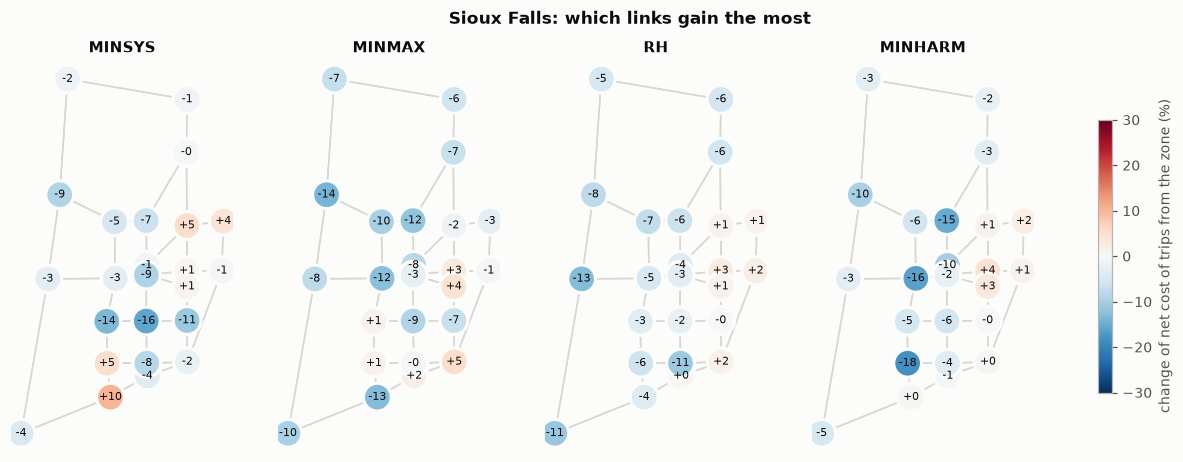

In [ ]:
def origin_map(result, method, ax, limit=0.3):
    """Mean change of net cost of the trips starting in each zone."""
    outcome = result["outcomes"][method, True]
    by_origin = (outcome.net_cost * outcome.demand).groupby("origin").sum() / (outcome.cost_before * outcome.demand).groupby("origin").sum() - 1
    nodes = result["nodes"].loc[by_origin.index]
    for link in result["links"].itertuples():
        a, b = result["nodes"].geometry[link.a_node], result["nodes"].geometry[link.b_node]
        ax.plot([a.x, b.x], [a.y, b.y], color="#d8d7d2", lw=1, zorder=1)
    points = ax.scatter(nodes.geometry.x, nodes.geometry.y, c=100 * by_origin, cmap="RdBu_r", vmin=-100 * limit, vmax=100 * limit, s=330, edgecolor="#fcfcfb", lw=2, zorder=2)
    for node_id, node in nodes.iterrows():
        ax.annotate(f"{100 * by_origin[node_id]:+.0f}", (node.geometry.x, node.geometry.y), ha="center", va="center", fontsize=7, color=INK, zorder=3)
    ax.set_title(method)
    ax.set_axis_off()
    return points

fig, axes = plt.subplots(1, 4, figsize=(15, 4.6))
for ax, method in zip(axes, ["MINSYS", "MINMAX", "RH", "MINHARM"]):
    points = origin_map(results["sioux-falls"], method, ax)
fig.colorbar(points, ax=axes, shrink=0.7, label="change of net cost of trips from the node (%)")
fig.suptitle("Sioux Falls: which nodes gain the most", fontweight="bold")
save(fig, "sioux_falls_map")

## All networks, all methods

In [13]:
# fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey="row")
# for column, (name, methods) in enumerate(NETWORKS.items()):
#     table = summaries[name]
#     x = np.arange(len(methods))
#     for row, (measure, label) in enumerate([("share_worse_off", "share of trips worse off"), ("max_ratio", "worst ratio: net cost after / before")]):
#         ax = axes[row, column]
#         for k, (revenue, hatch) in enumerate([("kept", None), ("refunded", "////")]):
#             values = [table[measure].get((m, revenue), table[measure].get((m, "revenue neutral"), np.nan)) for m in methods]
#             bars = ax.bar(x + (k - 0.5) * 0.4, values, 0.36, color=[COLOR[m] for m in methods], alpha=1.0 if hatch is None else 0.55,
#                           hatch=hatch, edgecolor="#fcfcfb", label=f"revenue {revenue}" if hatch is None else "revenue refunded equally")
#             for xi, value in zip(x + (k - 0.5) * 0.4, values):
#                 ax.annotate(f"{value:.2f}", (xi, value), ha="center", va="bottom", fontsize=7, color=MUTED)
#         if measure == "max_ratio":
#             ax.axhline(1, color=INK, lw=0.8)
#         ax.set_xticks(x, [m.replace("_", "/") for m in methods], rotation=30, ha="right")
#         ax.grid(axis="x", visible=False)
#         if row == 0:
#             ax.set_title(name)
#         if column == 0:
#             ax.set_ylabel(label)
# from matplotlib.patches import Patch
# axes[0, 0].legend(handles=[Patch(color="#8a8984", label="revenue kept"), Patch(facecolor="#c9c8c2", hatch="////", edgecolor="#fcfcfb", label="revenue refunded equally")], fontsize=8, loc="upper center")
# plt.tight_layout()
# save(fig, "fairness_by_method")

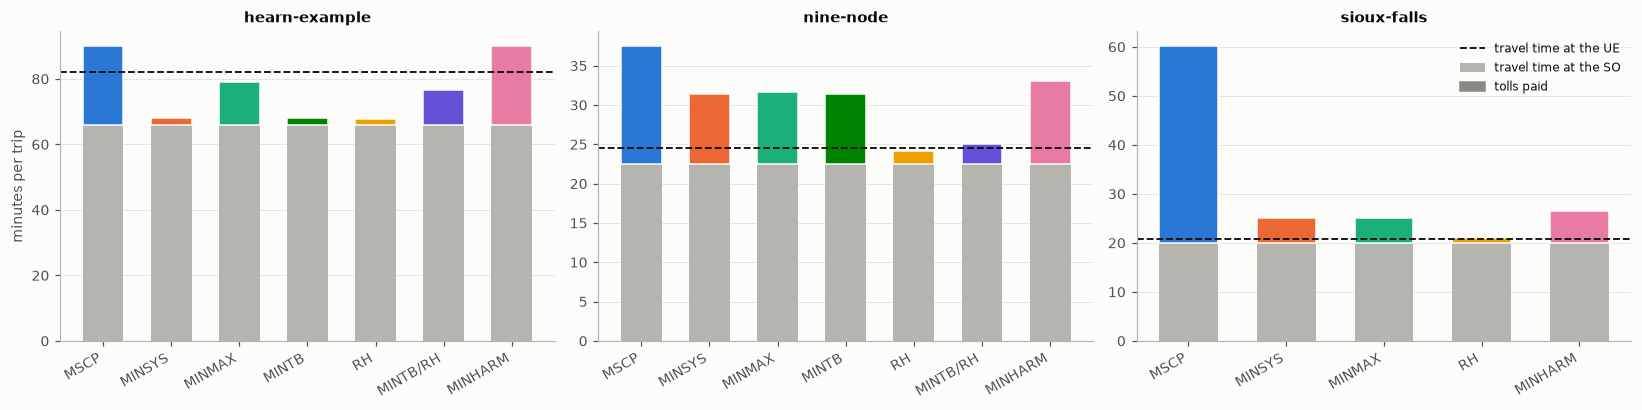

In [17]:
from matplotlib.patches import Patch
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (name, methods) in zip(axes, NETWORKS.items()):
    result, table = results[name], summaries[name]
    trips = result["demand"].sum()
    time = fa.total_time(result["links"], result["so"]) / trips
    revenue = [(result["tolls"][m] * result["so"]).sum() / trips for m in methods]
    paid = [(result["tolls"][m].clip(lower=0) * result["so"]).sum() / trips for m in methods]
    x = np.arange(len(methods))
    ax.bar(x, [time] * len(methods), 0.6, color="#b5b4ae", label="travel time at the SO")
    ax.bar(x, paid, 0.6, bottom=time, color=[COLOR[m] for m in methods], edgecolor="#fcfcfb", label="tolls paid")
    ax.axhline(fa.total_time(result["links"], result["ue"]) / trips, color=INK, lw=1.2, ls="--", label="travel time at the UE")
    ax.set_xticks(x, [m.replace("_", "/") for m in methods], rotation=30, ha="right")
    ax.set(title=name, ylabel="minutes per trip" if name == "hearn-example" else None)
    ax.grid(axis="x", visible=False)
axes[2].legend(handles=axes[2].get_legend_handles_labels()[0][:2] + [Patch(color="#8a8984", label="tolls paid")], fontsize=8, loc="upper right")
plt.tight_layout()
save(fig, "cost_per_trip")

The grey block is what travellers spend on the road at the SO, the coloured block what they pay in tolls on top, and the dashed line what they spent before. The gap between the dashed line and the grey block is the efficiency gain.

## Comments 

1. The system optimum is not fair in travel time. It sends travellers of the same O-D pair on routes of different length (up to 48 % in Sioux Falls) and makes some O-D pairs slower. Tolls restore equal treatment within a pair in terms of time plus toll.
2. Without a refund, first-best tolls hurt nearly everyone. The time saved (4 % in Sioux Falls, 8 % on nine node) is far smaller than the tolls (26 % to 200 % of travel time).
3. The method matters as much as the refund. All methods are equally efficient, but the worst-off group's cost ratio in Sioux Falls ranges from 1.24 (MINHARM) to 2.43 (MSCP) with a refund.
4. A Pareto-improving first-best toll with a uniform refund exists on the two small networks but not on Sioux Falls where about 40 % of trips, mostly long ones, lose under every method tried.